# Stray light in Caldwell's lens

Notebook 166 (non-sequential ray tracing) introduced `pyoptics.nsrt`. Here
it analyses a real lens: J. B. Caldwell's all fused silica KrF lithography
lens (248.3 nm, 4x reduction, image side NA 0.56, image field 23.4 mm,
notebook 50 (magnification, distortion and telecentricity)), put into two
mounts:

- a **closed barrel**: the lens barrel of `cad.Mount`
  (notebook 162, CAD export of lens systems), in which spacers fill the bore up to the beam,
- **three-pad cells**: an invented mount in which every lens is glued into
  a cell ring at only three azimuths (a common way to hold large lenses
  without stress). The rest of the rim is free, with a radial gap of 2 mm,
  so light can pass *next to* the lens elements.

Light that reaches the wafer on any path other than the design path is
*false light* (flare): double reflections at the lens surfaces (ghosts),
light scattered by the mount, and light that sneaks through the gaps. In
a scanner the wafer sees the image of a slit-shaped part of the reticle,
so the end result here is a **map of false light over the scan slit**,
and what it does to the image contrast and the process window.

Everything mechanical below (cells, pads, finishes, gaps, the iris) is
invented for this notebook, with plausible numbers; the optical design is
Caldwell's.

> **Known limitation, for a later fix:** the invented supports are not
> fitted to the lens shapes. In places the cell rings and pads of one lens
> intersect the neighbouring lens elements (visible in the section plots
> below). The tracer does not check for overlapping solids, so rays there
> see a physically impossible geometry. The mount results are therefore an
> illustration of the method in principle, not a mechanical design; the
> ghost results and the false light map of the lens itself are not
> affected.

In [1]:
import time

import numpy as np
import matplotlib.pyplot as plt
import build123d as bd

from pyoptics import raytrace as rt
from pyoptics import nsrt, cad
from pyoptics.coatings import Coating, Layer

plt.rcParams.update({"figure.dpi": 80, "font.size": 11, "figure.facecolor": "white",
                     "axes.facecolor": "#fcfcfb", "savefig.facecolor": "white",
                     "axes.grid": True, "grid.color": "0.88", "grid.linewidth": 0.6,
                     "axes.axisbelow": True, "axes.spines.top": False, "axes.spines.right": False})
t_start = time.time()

lens = rt.caldwell_krf_lens()
LAM = lens.wavelength
NA_OBJ = 0.14   # object side NA (0.56/4)
MECH = cad.Mechanics(margin=3.0, bevel=0.5)
print(lens.surfaces.__len__(), "surfaces,", len(lens.elements()), "lenses, track {:.0f} mm".format(
    lens.image_z + lens.object_distance))

42 surfaces, 21 lenses, track 1000 mm


## 1. The lens and its two mounts

`Scene.add_system()` turns the lens prescription into analytic faces: the
optical surfaces up to their clear apertures, the lands from there to the
45 degree bevels, and the cylindrical rims, with the same `cad.Mechanics`
as the STEP export (here 3 mm of rim outside the clear aperture and 0.5 mm
bevels). The optical surfaces are polished (Fresnel, with an AR coating,
section 3), the bevels and rims are fine-ground glass (`ground_glass()`:
Lambertian scatter, 4 % back into the air and 90 % into the glass).

The aperture stop of the design is a lens surface (surface 30, index 29).
Without a physical stop, light beyond the design NA would pass the
polished land around it, so the land of that surface is blackened: an
iris painted onto the glass.

The **closed barrel** comes straight from `cad.Mount`: rings and spacers
cut to the lenses, with a bore that follows the beam. The **three-pad
cells** are built here with build123d: per lens a 3 mm thick cell ring from
2 mm outside the rim to the barrel wall, three glue pads at 90, 210 and 330
degrees that bridge the gap, and a plain barrel tube. Each mount comes in
with properties by label (see notebook 166, non-sequential ray tracing):
`"cell_*"`, `"pad_*"`, `"barrel"`, `"spacer_*"` and so on.

In [2]:
def ar_coatings(layers):
    "Coatings {surface index: Coating} for all air-glass surfaces, from the air side."
    out = {}
    for k in range(len(lens.surfaces)):
        n1, n2 = lens.n[k], lens.n[k + 1]
        if n1 == n2:
            continue
        ls = [Layer(n, t) for n, t in layers]
        out[k] = Coating(ls if n1 == 1.0 else ls[::-1]) if ls else None
    return out


COATINGS = {"bare": [],
            "MgF2 single layer": [(1.415, LAM/(4*1.415))],
            "two layer V-coat": [(1.415, 43.87e-6), (1.69, 36.73e-6)]}  # MgF2 / Al2O3, see section 3


def lens_scene(coating="two layer V-coat", **kwargs):
    "Caldwell's lens with lands, bevels, rims, the painted iris and the wafer detector."
    scene = nsrt.Scene(wavelength=LAM)
    scene.add_system(lens, mechanics=MECH, coatings=ar_coatings(COATINGS[coating]), **kwargs)
    scene.face("L15:S30 land").property = nsrt.black_paint()   # the iris
    return scene


base = lens_scene()
RIMS = [(f.label.split()[0], f.radius, f.origin[2] + f.z0, f.origin[2] + f.z1)
        for f in base.faces if f.label.endswith(" rim")]
GAP = 2.0


def three_pad_cells(gap=GAP, pad_width=6.0, cell=3.0, wall=3.0, azimuths=(90.0, 210.0, 330.0)):
    "Cell rings with three glue pads per lens and a barrel tube (build123d solids, mm)."
    Rb = max(r[1] for r in RIMS) + gap + 4.0
    parts = []
    for name, rm, z0, z1 in RIMS:
        zc, tc = 0.5*(z0 + z1), min(cell, z1 - z0)
        pl = bd.Plane(origin=(0, 0, zc - tc/2))
        ring = bd.Solid.make_cylinder(Rb, tc, pl) - bd.Solid.make_cylinder(rm + gap, tc, pl)
        ring.label = "cell_" + name
        parts.append(ring)
        shell = bd.Solid.make_cylinder(rm + gap, tc, pl) - bd.Solid.make_cylinder(rm, tc, pl)
        for j, az in enumerate(azimuths):
            box = bd.Box(2*(rm + gap) + 2, pad_width, tc + 2).located(bd.Location((rm + gap + 1, 0, zc)))
            pad = (shell & box.rotate(bd.Axis.Z, az)).solids()[0]
            pad.label = "pad_{}{}".format(name, "abc"[j])
            parts.append(pad)
    zf, zb = RIMS[0][2] - 10, RIMS[-1][3] + 10
    barrel = bd.Solid.make_cylinder(Rb + wall, zb - zf, bd.Plane(origin=(0, 0, zf))) - \
        bd.Solid.make_cylinder(Rb, zb - zf, bd.Plane(origin=(0, 0, zf)))
    barrel.label = "barrel"
    return parts + [barrel]


CELLS = three_pad_cells()


def build(mount, finish=None, coating="two layer V-coat", gap_tags=True):
    "The lens in a mount ('closed' or 'pads'); finish of the metal parts (default black anodized)."
    finish = finish or nsrt.black_anodized()
    if mount == "closed":
        return lens_scene(coating, mount=cad.Mount(), mount_property=finish)
    scene = lens_scene(coating)
    scene.add_shapes(CELLS, property={"cell_*": finish, "barrel": finish,
                                      "pad_*": nsrt.diffuse(0.3)},  # white-ish epoxy
                     tolerance=0.01)
    if gap_tags:
        # transparent tags in the gaps, so that the ray histories show who passed them
        for name, rm, z0, z1 in RIMS:
            scene.add(nsrt.ConicFace(np.inf, rm + GAP, r_min=rm, position=(0, 0, 0.5*(z0 + z1)),
                                     property=nsrt.ideal(), label="gap_" + name, detector=True))
    return scene


t = time.time()
closed, pads = build("closed"), build("pads")
print("scenes built in {:.0f} s: {} and {}".format(time.time() - t, closed, pads))

scenes built in 4 s: Scene(171 faces, 1 meshes) and Scene(254 faces, 1 meshes)


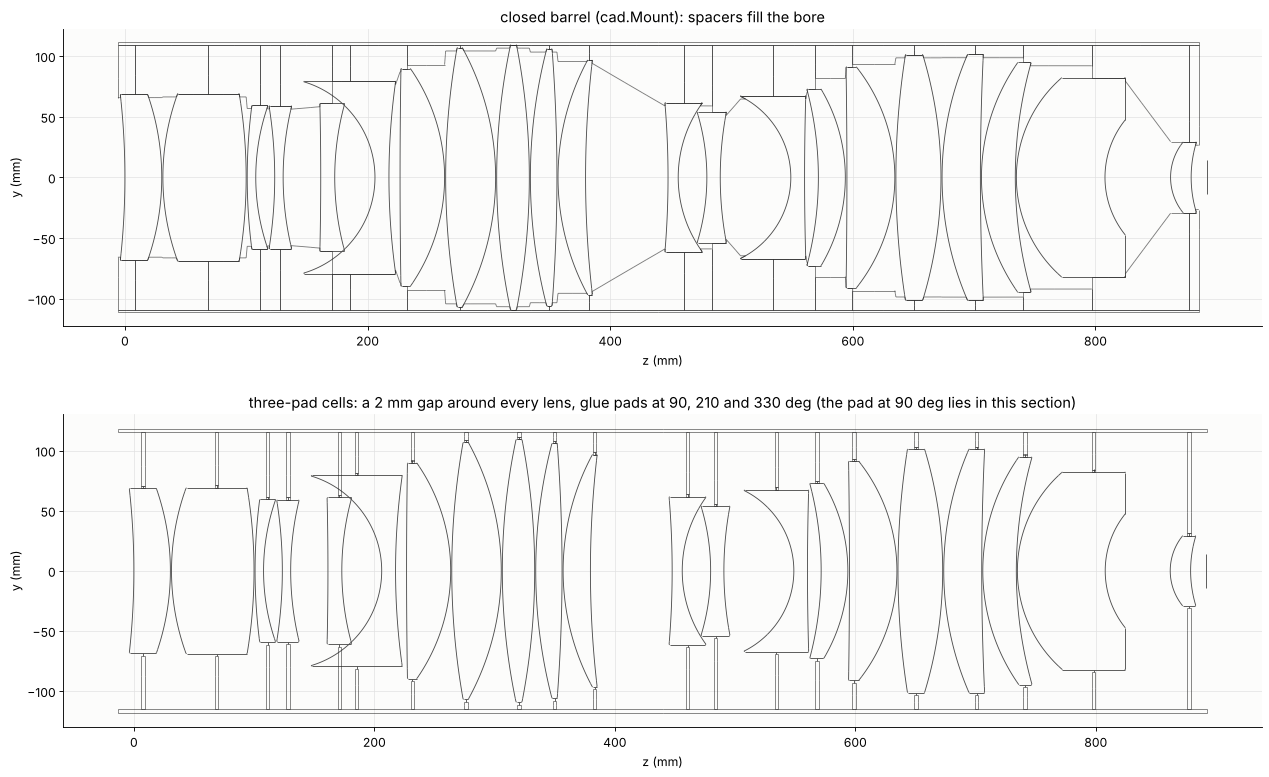

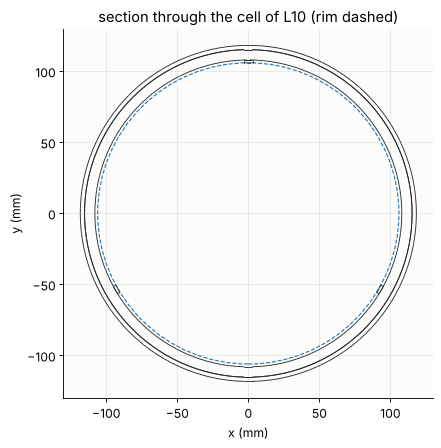

In [3]:
fig = plt.figure(figsize=(16, 10))
ax = fig.add_subplot(2, 1, 1)
nsrt.plot_scene(closed, ax)
ax.set(title="closed barrel (cad.Mount): spacers fill the bore", xlabel="z (mm)", ylabel="y (mm)")
ax = fig.add_subplot(2, 1, 2)
nsrt.plot_scene(pads, ax)
ax.set(title="three-pad cells: a 2 mm gap around every lens, glue pads at 90, 210 and 330 deg "
       "(the pad at 90 deg lies in this section)", xlabel="z (mm)", ylabel="y (mm)")
plt.tight_layout()
plt.show()

name, rm, z0, z1 = RIMS[9]
fig, ax = plt.subplots(figsize=(6, 6))
nsrt.plot_scene(pads, ax, plane="xy", offset=0.5*(z0 + z1), mesh_alpha=1.0)
ax.add_patch(plt.Circle((0, 0), rm, fill=False, ls="--", color="C0"))
ax.set(title="section through the cell of {} (rim dashed)".format(name), xlabel="x (mm)",
       ylabel="y (mm)")
plt.show()

## 2. Check: the non-sequential trace reproduces the sequential one

With ideal faces (T = 1, no reflections) and absorbing lands, bevels and
rims, rays from the reticle land on the wafer exactly where
`System.trace()` puts them.

In [4]:
check = nsrt.Scene(wavelength=LAM)
check.add_system(lens, mechanics=MECH, property=nsrt.ideal(), land=nsrt.absorber(),
                 bevel=nsrt.absorber(), rim=nsrt.absorber())
rng = np.random.default_rng(0)
for field in (0.0, 30.0, 46.8):
    r, a = 0.97*np.sqrt(rng.random(500)), 2*np.pi*rng.random(500)
    rays = lens.rays(field, r*np.cos(a), r*np.sin(a))
    b = lens.trace(rays)
    h = check.trace(nsrt.RaySet(rays.points, rays.directions, np.ones(500))).hits["image"]
    ref = lens.to_image_frame(b.points[-1][b.valid])
    dev = np.min(np.linalg.norm(h.points[:, None, :2] - ref[None, :, :2], axis=-1), axis=1)
    print("field {:4.1f} mm: {} of {} rays on the wafer, largest deviation {:.1e} mm".format(
        field, len(h), b.valid.sum(), dev.max()))

field  0.0 mm: 500 of 500 rays on the wafer, largest deviation 5.1e-13 mm
field 30.0 mm: 500 of 500 rays on the wafer, largest deviation 5.9e-13 mm
field 46.8 mm: 494 of 494 rays on the wafer, largest deviation 6.0e-13 mm


## 3. Ghosts and AR coatings

Every one of the 42 air-glass surfaces reflects. Light reflected twice,
once backwards and once forwards again, travels on towards the wafer as a
defocused ghost; with 42 surfaces there are 42·41/2 = 861 such double
reflection paths. In split mode the trace follows all of them for every
ray (`max_reflections=2` stops the higher orders, which are R² times
weaker again).

Three coatings at 248.3 nm (dispersion of the films neglected):

- bare fused silica: R = 4.1 %,
- a quarter wave of MgF2 (n = 1.415): R = 2.0 % (the film index is too
  high for fused silica to cancel the reflection),
- a two layer V-coat, MgF2 on Al2O3 (n = 1.69), thicknesses optimized here
  for zero reflection at normal incidence: R = 0.08 % at 0 degrees,
  0.3 % at 30 degrees.

The source is one point on the reticle at 30 mm height (7.5 mm on the
wafer), filling the object side NA of 0.14.

In [5]:
from scipy.optimize import minimize

ns = lens.n[1]


def R_coat(layers, angle=0.0):
    c = Coating([Layer(n, t) for n, t in layers])
    p = c.power(np.atleast_1d(angle), 1.0, ns, wavelength=LAM)
    return float(0.5*(p["R_s"] + p["R_p"])[0])


opt = minimize(lambda t: R_coat([(1.415, t[0]*1e-6), (1.69, t[1]*1e-6)]), [44, 37],
               method="Nelder-Mead")
print("V-coat: MgF2 {:.2f} nm on Al2O3 {:.2f} nm".format(*opt.x*1e-6*1e6))
for name, layers in COATINGS.items():
    print("  {:18s} R(0 deg) = {:.3%}, R(30 deg) = {:.3%}".format(
        name, R_coat(layers), R_coat(layers, np.radians(30))))

point = nsrt.system_source(lens, 30.0, 1500, rng=1)
ghosts = {}
for name in COATINGS:
    sc = lens_scene(name, mount=None)
    t = time.time()
    res = sc.trace(point, min_weight=1e-7, max_reflections=2, max_scatters=1, rng=2)
    h = res.hits["image"]
    direct = h.mask(reflections=0, scatters=0)
    ghost = h.mask(reflections=2, scatters=0)
    ghosts[name] = (h, direct, ghost)
    print("{:18s} {:4.0f} s: image {:.3f}, ghosts {:.2e} = {:.3%} of the image".format(
        name, time.time() - t, h.weights[direct].sum(), h.weights[ghost].sum(),
        h.weights[ghost].sum()/h.weights[direct].sum()))

V-coat: MgF2 43.87 nm on Al2O3 36.73 nm
  bare               R(0 deg) = 4.108%, R(30 deg) = 4.262%
  MgF2 single layer  R(0 deg) = 1.979%, R(30 deg) = 2.110%
  two layer V-coat   R(0 deg) = 0.078%, R(30 deg) = 0.303%


bare                  9 s: image 0.171, ghosts 1.16e-02 = 6.820% of the image


MgF2 single layer    10 s: image 0.430, ghosts 7.90e-03 = 1.837% of the image


two layer V-coat     10 s: image 0.960, ghosts 3.63e-05 = 0.004% of the image


strongest ghosts with the V-coat (power per unit source power):


  1.45e-06  L21:S42 R -> L21:S41 R
  9.39e-07  L21:S42 R -> L20:S40 R
  8.04e-07  L10:S20 R -> L6:S12 R
  7.11e-07  L12:S23 R -> L7:S13 R
  6.94e-07  L13:S25 R -> L12:S23 R
  6.66e-07  L17:S34 R -> L16:S32 R
  6.11e-07  L21:S41 R -> L20:S40 R
  5.90e-07  L19:S38 R -> L18:S36 R


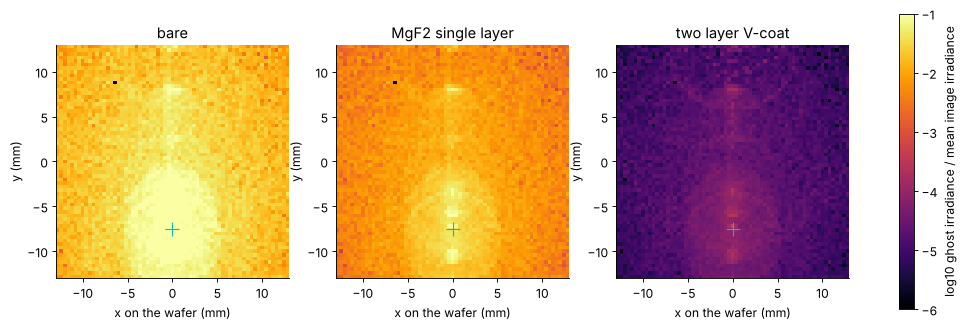

In [6]:
h, direct, ghost = ghosts["two layer V-coat"]
print("strongest ghosts with the V-coat (power per unit source power):")
for p, n, path in h.select(ghost).paths(8):
    print("  {:.2e}  {}".format(p, path))

fig, axs = plt.subplots(1, 3, figsize=(16, 4.8))
for ax, (name, (h, direct, ghost)) in zip(axs, ghosts.items()):
    E, xe, ye = h.irradiance(65, ((-13, 13), (-13, 13)), mask=ghost)
    E0 = h.weights[direct].sum()/(np.pi*11.7**2)  # mean irradiance if the image light filled the field
    im = ax.imshow(np.log10(np.maximum(E.T/E0, 1e-7)), extent=(xe[0], xe[-1], ye[0], ye[-1]),
                   origin="lower", cmap="inferno", vmin=-6, vmax=-1)
    ax.plot(*h.points[direct][:, :2].mean(0), "c+", ms=12)
    ax.set(title=name, xlabel="x on the wafer (mm)", ylabel="y (mm)")
    ax.grid(False)
fig.colorbar(im, ax=axs, label="log10 ghost irradiance / mean image irradiance")
plt.show()

The ghosts of a point form a halo of overlapping, defocused disks around
the image (cyan cross) and across the whole field. Their total falls with
R², from a few per cent of the image without coating to well below 0.1 %
with the V-coat: AR coatings are what makes a 42-surface lens usable at
all. From here on all lenses carry the V-coat.

## 4. False light over the scan slit

A scanner exposes the wafer through a slit: the reticle is illuminated in
a slit-shaped area, and reticle and wafer move together. Here the slit is
20 × 6 mm on the wafer (80 × 24 mm on the reticle, inside the 23.4 mm image
field), illuminated uniformly and telecentrically (Caldwell's lens is
telecentric on the object side) with a filled pupil (sigma = 1).

### 4a. The ghosts of the slit

Every point of the slit has its ghost halo (section 3), and the halos of
all points add up to a false light background over the slit. The ghost
paths are followed exactly in split mode, so the map is smooth. False
light is given relative to the mean image irradiance in the slit.

MgF2 single layer   50 s: ghost false light in the slit 0.771% of the image


two layer V-coat    33 s: ghost false light in the slit 0.001% of the image


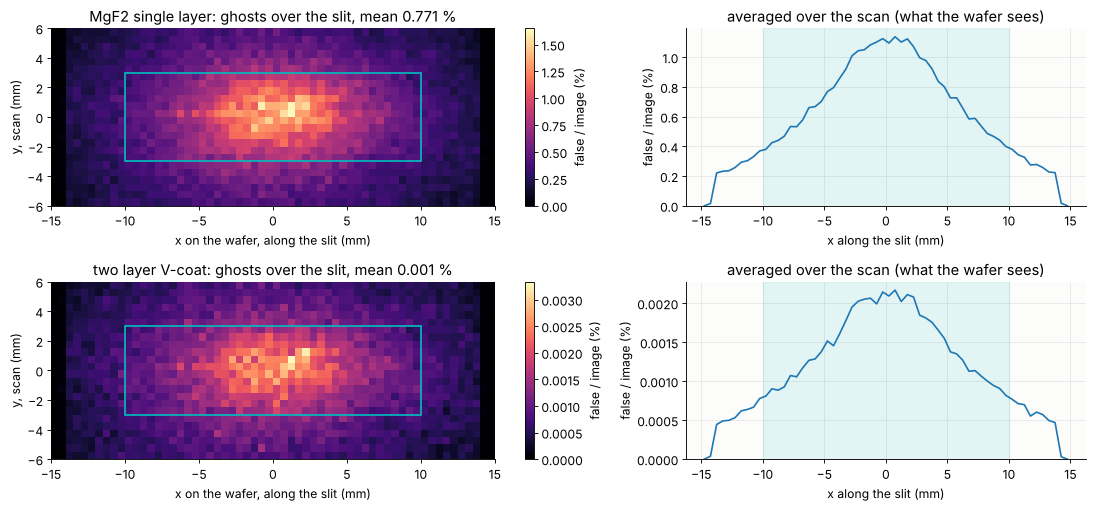

In [7]:
SLIT = (20.0, 6.0)          # on the wafer, mm


def slit_source(n, na0, na1, rng, power=1.0):
    "Uniform telecentric illumination of the reticle slit, directions uniform in NA na0..na1."
    rng = np.random.default_rng(rng)
    x = rng.uniform(-2*SLIT[0], 2*SLIT[0], n)
    y = rng.uniform(-2*SLIT[1], 2*SLIT[1], n)
    r = np.sqrt(rng.uniform(na0**2, na1**2, n))
    a = rng.uniform(0, 2*np.pi, n)
    d = np.c_[r*np.cos(a), r*np.sin(a), np.sqrt(1 - r**2)]
    return nsrt.RaySet(np.c_[x, y, np.full(n, -lens.object_distance)], d, np.full(n, power/n))


def in_slit(h):
    return (np.abs(h.points[:, 0]) <= SLIT[0]/2) & (np.abs(h.points[:, 1]) <= SLIT[1]/2)


def classify(h):
    "Masks of the image light and of the kinds of false light."
    gaps = h.mask(faces=["gap_*"], events="T")
    sca = h.mask(scatters=(1, 99))
    return {"image": h.mask(reflections=0, scatters=0) & ~gaps,
            "ghosts": h.mask(reflections=(1, 99), scatters=0) & ~gaps,
            "mount and rims": sca & ~gaps, "through the gaps": gaps}


BINS, RANGE = (60, 24), ((-15, 15), (-6, 6))
AREA = SLIT[0]*SLIT[1]
inside = slit_source(3000, 0.0, NA_OBJ, 10)
slit_ghosts = {}
for coating in ("MgF2 single layer", "two layer V-coat"):
    t = time.time()
    h = lens_scene(coating, mount=cad.Mount(), mount_property=nsrt.black_anodized()).trace(
        inside, min_weight=1e-6, max_reflections=2, max_scatters=1, rng=12).hits["image"]
    c = classify(h)
    E_img = h.weights[c["image"] & in_slit(h)].sum()/AREA
    E, xe, ye = h.irradiance(BINS, RANGE, mask=c["ghosts"])
    slit_ghosts[coating] = (E/E_img, h.weights[c["ghosts"] & in_slit(h)].sum()/AREA/E_img)
    print("{:18s} {:3.0f} s: ghost false light in the slit {:.3%} of the image".format(
        coating, time.time() - t, slit_ghosts[coating][1]))

fig, axs = plt.subplots(2, 2, figsize=(15, 6.5), gridspec_kw={"width_ratios": [3, 2]})
for row, (coating, (m, F)) in enumerate(slit_ghosts.items()):
    ax = axs[row, 0]
    im = ax.imshow(100*m.T, extent=(*RANGE[0], *RANGE[1]), origin="lower", cmap="magma", vmin=0)
    ax.add_patch(plt.Rectangle((-SLIT[0]/2, -SLIT[1]/2), *SLIT, fill=False, color="c", lw=1.5))
    ax.set(title="{}: ghosts over the slit, mean {:.3f} %".format(coating, 100*F),
           xlabel="x on the wafer, along the slit (mm)", ylabel="y, scan (mm)")
    ax.grid(False)
    fig.colorbar(im, ax=ax, label="false / image (%)", fraction=0.025)
    xc = 0.5*(xe[1:] + xe[:-1])
    yc = 0.5*(ye[1:] + ye[:-1])
    axs[row, 1].plot(xc, 100*m[:, np.abs(yc) <= SLIT[1]/2].mean(1))
    axs[row, 1].axvspan(-SLIT[0]/2, SLIT[0]/2, color="c", alpha=0.1)
    axs[row, 1].set(xlabel="x along the slit (mm)", ylabel="false / image (%)", ylim=(0, None),
                    title="averaged over the scan (what the wafer sees)")
plt.tight_layout()
plt.show()

The ghosts of the slit form a broad background that spills beyond the
slit, because each point's halo is spread over a large part of the
field. The scan averages over y, so what the wafer sees is the profile on
the right: a flare that varies along the slit, i.e. a different
background (and CD) in the middle and at the ends of the slit. With the
single MgF2 layer this is of the order of a per cent of the image; the
V-coat takes it down roughly by the ratio of the squared reflectances.

### 4b. The mount: light beyond the NA and the gaps next to the lenses

A patterned reticle also sends light *beyond* the NA: a dense pattern
diffracts orders that the lens cannot accept. In the design they are just
lost; in the real lens they hit the lands, bevels, rims and the mount,
and in the three-pad cells they also pass the gaps next to the lenses.
That light is traced with directions uniform in the direction cosines
from NA 0.16 to 0.6, with a power eta per unit of in-NA light (eta = 0.3,
an assumption typical of fine dense lines), together with the in-NA light
whose reflections also wander off into the mount. The lens carries the
V-coat. Three mounts: the closed barrel and the three-pad cells, both
black anodized, and the three-pad cells in bare machined aluminium.

The false light is sorted by the ray histories: ghosts (reflections, no
scatter), mount and rims (at least one scatter on metal, glue pads,
ground rims and bevels), and through the gaps (rays that passed one of the
transparent tags in the gaps). The light beyond the NA is traced in five
independent batches to estimate the Monte Carlo error.

In [8]:
ETA = 0.3
mounts = {"closed barrel, black anodized": ("closed", None),
          "three-pad cells, black anodized": ("pads", None),
          "three-pad cells, bare aluminium": ("pads", nsrt.machined_metal())}
KINDS = ("ghosts", "mount and rims", "through the gaps")
table, gap_power, scenes = {}, {}, {}
for name, (kind, finish) in mounts.items():
    sc = build(kind, finish)
    scenes[name] = sc
    t = time.time()
    r_in = sc.trace(inside, min_weight=1e-6, max_reflections=2, max_scatters=2, rng=12)
    h = r_in.hits["image"]
    c = classify(h)
    E_img = h.weights[c["image"] & in_slit(h)].sum()/AREA
    row = {k: [h.weights[c[k] & in_slit(h)].sum()/AREA/E_img] for k in KINDS}
    gaps = {k: v.power for k, v in r_in.hits.items() if k.startswith("gap_")}
    batches = {k: [] for k in KINDS}
    for b in range(5):
        r_out = sc.trace(slit_source(30000, 0.16, 0.6, 100 + b, ETA), min_weight=1e-3,
                         max_reflections=2, max_scatters=2, n_scatter=2, rng=200 + b)
        h = r_out.hits["image"]
        c = classify(h)
        for k in KINDS:
            batches[k].append(h.weights[c[k] & in_slit(h)].sum()/AREA/E_img)
        for k, v in r_out.hits.items():
            if k.startswith("gap_"):
                gaps[k] += v.power/5
    for k in KINDS:
        v = np.array(batches[k])
        row[k] += [v.mean(), v.std(ddof=1)/np.sqrt(len(v))]
    table[name], gap_power[name] = row, gaps
    print("{:32s} traced in {:.0f} s".format(name, time.time() - t))

print("\nfalse light in the slit relative to the image (in-NA light | beyond the NA +- error):")
for name, row in table.items():
    print(name)
    for k in KINDS:
        print("   {:17s} {:9.5f} % | {:9.5f} % +- {:.5f} %".format(k, 100*row[k][0], 100*row[k][1],
                                                                  100*row[k][2]))
    print("   {:17s} {:9.5f} %".format("total", 100*sum(row[k][0] + row[k][1] for k in KINDS)))

closed barrel, black anodized    traced in 52 s


three-pad cells, black anodized  traced in 48 s


three-pad cells, bare aluminium  traced in 66 s

false light in the slit relative to the image (in-NA light | beyond the NA +- error):
closed barrel, black anodized
   ghosts              0.00149 % |   0.00008 % +- 0.00000 %
   mount and rims      0.00001 % |   0.00012 % +- 0.00002 %
   through the gaps    0.00000 % |   0.00000 % +- 0.00000 %
   total               0.00169 %
three-pad cells, black anodized
   ghosts              0.00149 % |   0.00001 % +- 0.00000 %
   mount and rims      0.00002 % |   0.00031 % +- 0.00013 %
   through the gaps    0.00000 % |   0.00009 % +- 0.00009 %
   total               0.00192 %
three-pad cells, bare aluminium
   ghosts              0.00167 % |   0.00001 % +- 0.00000 %
   mount and rims      0.00003 % |   0.00030 % +- 0.00010 %
   through the gaps    0.00001 % |   0.00016 % +- 0.00010 %
   total               0.00218 %


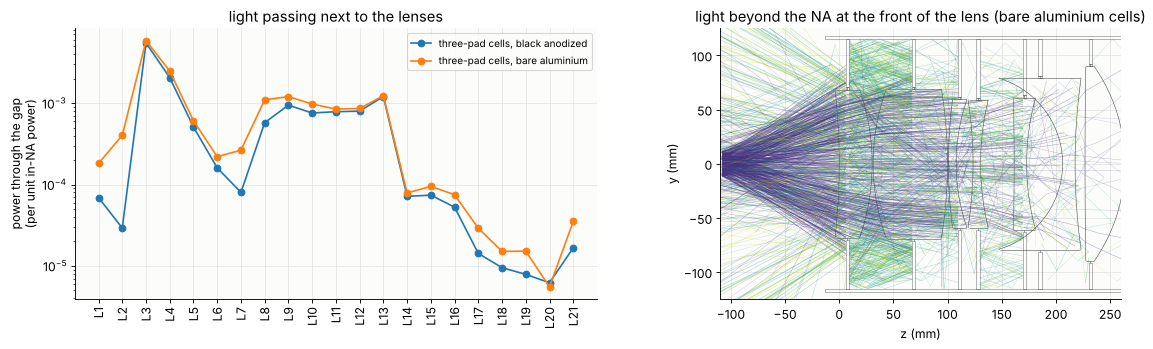

bare aluminium cells, strongest stray paths of the light beyond the NA onto the slit:
   5.3e-06 (  1 rays)  cell_L5 R
   1.8e-06 (  1 rays)  L5:S10 bevel s -> L6 rim s
   7.8e-07 (  1 rays)  cell_L8 S
   6.2e-07 (  1 rays)  cell_L5 S
   5.9e-07 (  1 rays)  cell_L9 S
   3.6e-07 (  1 rays)  cell_L10 R -> barrel R -> cell_L9 S


In [9]:
fig, axs = plt.subplots(1, 2, figsize=(15, 4.5))
names = [f[0] for f in RIMS]
for name in ("three-pad cells, black anodized", "three-pad cells, bare aluminium"):
    g = gap_power[name]
    axs[0].semilogy(range(len(names)), [max(g["gap_" + n], 1e-9) for n in names], "o-", label=name)
axs[0].set(xticks=range(len(names)), xticklabels=names,
           ylabel="power through the gap\n(per unit in-NA power)", title="light passing next to the lenses")
axs[0].tick_params(axis="x", rotation=90)
axs[0].legend(fontsize=9)

# a few traced rays beyond the NA in the three-pad mount, to see where they go
sc = scenes["three-pad cells, bare aluminium"]
demo = sc.trace(slit_source(400, 0.3, 0.6, 7), min_weight=1e-2, max_reflections=3,
                max_scatters=1, record=True, rng=8)
nsrt.plot_scene(sc, axs[1], lw=0.5)
nsrt.plot_rays(demo, axs[1], max_rays=400, lw=0.4)
axs[1].set(xlim=(-110, 260), ylim=(-125, 125), xlabel="z (mm)", ylabel="y (mm)",
           title="light beyond the NA at the front of the lens (bare aluminium cells)")
plt.tight_layout()
plt.show()

h = sc.trace(slit_source(30000, 0.16, 0.6, 300, ETA), min_weight=1e-3, max_reflections=2,
             max_scatters=2, n_scatter=2, rng=301).hits["image"]
c = classify(h)
sel = h.select(in_slit(h) & (c["mount and rims"] | c["through the gaps"]))
print("bare aluminium cells, strongest stray paths of the light beyond the NA onto the slit:")
for p, n, path in sel.paths(6, events="RSs"):
    print("   {:.1e} ({:3d} rays)  {}".format(p, n, path[:110]))

What the numbers say:

- **Ghosts dominate.** With the single MgF2 layer the double reflection
  ghosts of the slit add 0.77 % false light, peaked in the middle of the
  slit (about 1.1 % in the centre, 0.4 % at the slit ends after the
  scan). The V-coat takes this down by almost three orders of magnitude.
- **The mount is a second order effect here**, at the 1e-6 level of the
  image: light beyond the NA that hits black anodized metal or a ground
  rim is mostly absorbed, and the little that is scattered rarely finds
  its way through the remaining lenses to the slit. The strongest single
  paths are specular reflections and scatter on the cell walls of the
  first lenses, and ground glass bevels and rims.
- **The gaps pass light, but not much of it reaches the wafer.** Up to
  0.5 % of the in-NA power passes next to L3 and L4, where the beam
  beyond the NA is widest; most of it is absorbed further on. Bare
  aluminium sends more light through the gaps than black anodizing
  (it reflects at the cell walls), but the total false light in the slit
  grows only by some 10 to 20 %.
- The Monte Carlo errors of the light beyond the NA are large (single
  rays carry most of it); more batches or targets at the slit
  (importance sampling) would tighten them, but they do not change the
  order of magnitude.

The mount numbers depend on the assumed eta and the invented geometry: a
lens with a larger NA, a mount with shiny edges in the beam, or a
reticle with much light beyond the NA can bring them into the per mille
range.

## 5. What false light does to the image: contrast and process window

False light adds an almost constant irradiance F (relative to the clear
field) to the aerial image. For dense lines and spaces the image is
I(x) = 1 + m cos(2 pi x/p) with modulation m; with flare it becomes
(I + F)/(1 + F): the dark lines are filled in, the contrast falls to
m/(1 + F), and the image log slope at the line edges (NILS) falls with
it. A threshold resist prints the line where the dose times the image
crosses the threshold, so a lower slope means a larger change of the
printed CD per per cent of dose error: the **exposure latitude** shrinks,
and since defocus lowers the contrast further, the usable depth of focus
at a given exposure latitude shrinks too: the **process window** gets
smaller. Notebook 152 (litho stochastics, flare and focus blur) treats the
long range flare of the surface roughness the same way.

The example: 250 nm lines and spaces (p = 500 nm) at NA 0.56, 248.3 nm,
conventional illumination sigma = 0.5, as an incoherent sum of two- and
three-beam interference with a Gaussian defocus loss of contrast, printed
to size at a threshold; exposure latitude = dose range for CD within
±10 %.

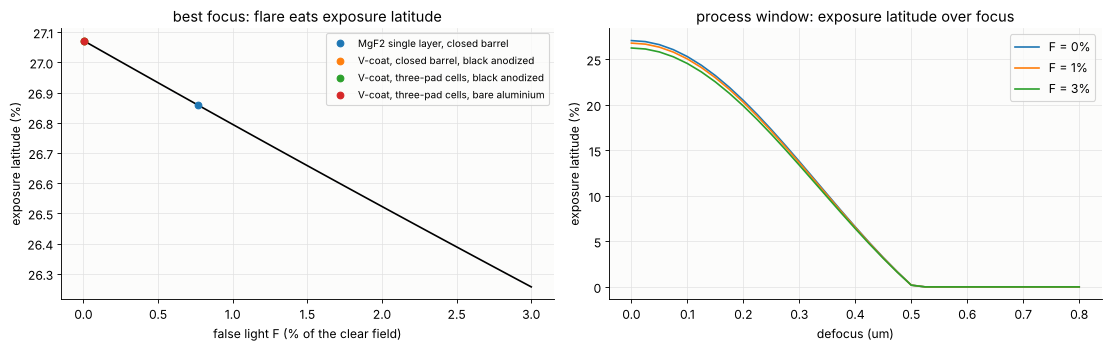

MgF2 single layer, closed barrel              F = 0.771%: contrast x 0.9924, exposure latitude 26.86% instead of 27.07%
V-coat, closed barrel, black anodized         F = 0.002%: contrast x 1.0000, exposure latitude 27.07% instead of 27.07%
V-coat, three-pad cells, black anodized       F = 0.002%: contrast x 1.0000, exposure latitude 27.07% instead of 27.07%
V-coat, three-pad cells, bare aluminium       F = 0.002%: contrast x 1.0000, exposure latitude 27.07% instead of 27.07%


In [10]:
lam_um, NA, pitch = 0.2483, 0.56, 0.5


def aerial(x, z, F):
    "Normalized aerial image of 1:1 lines (cos model with defocus z in um) plus flare F."
    f = 1/pitch
    # modulation of the first harmonic: partial coherence (sigma 0.5) reduces it slightly;
    # defocus: phase difference between the 0 and 1st orders averaged over the source
    m0 = 0.85
    dphi = np.pi*lam_um*z*f**2
    m = m0*np.exp(-0.5*(2*dphi*0.5*NA*0.5/(lam_um*f))**2)*np.cos(dphi)
    I = 1 + m*np.cos(2*np.pi*f*x)
    return (I + F)/(1 + F)


def cd(dose, z, F, threshold):
    x = np.linspace(0, pitch/2, 4001)
    I = dose*aerial(x, z, F)
    # resist line (dark) where I < threshold, centred at x = p/2: width = p - 2 x_edge
    above = I >= threshold
    if not above.any():
        return 0.0
    if above.all():
        return np.nan
    xe = x[np.argmin(above)]  # first x where I < threshold
    return pitch - 2*xe


def exposure_latitude(z, F, tol=0.1):
    "Dose range (relative to the dose 1 that prints to size in focus) with CD within +-tol of p/2 at defocus z."
    thr = cd_threshold(F)
    w = pitch/2
    # a line of width CD has its edges at x = (p - CD)/2 and prints there at the dose thr/I(x)
    x_wide, x_narrow = (pitch - w*(1 + tol))/2, (pitch - w*(1 - tol))/2
    I = aerial(np.array([x_wide, x_narrow]), z, F)
    if aerial(np.array([0.0]), z, F)[0] <= aerial(np.array([pitch/2]), z, F)[0]:
        return 0.0      # no contrast left (or reversed)
    D_wide, D_narrow = thr/I
    return max(D_narrow - D_wide, 0.0)


def cd_threshold(F):
    "Threshold that prints the line to size at best focus and dose 1."
    return float(aerial(np.array([pitch/4]), 0.0, F)[0])


flares = np.linspace(0, 0.03, 31)
EL0 = exposure_latitude(0.0, 0.0)
fig, axs = plt.subplots(1, 2, figsize=(14, 4.5))
axs[0].plot(100*flares, [100*exposure_latitude(0.0, F) for F in flares], "k-")
cases = {"MgF2 single layer, closed barrel": slit_ghosts["MgF2 single layer"][1]}
for name, row in table.items():
    cases["V-coat, " + name] = sum(row[k][0] + row[k][1] for k in KINDS)
for name, F in cases.items():
    axs[0].plot(100*F, 100*exposure_latitude(0.0, F), "o", label=name)
axs[0].set(xlabel="false light F (% of the clear field)", ylabel="exposure latitude (%)",
           title="best focus: flare eats exposure latitude")
axs[0].legend(fontsize=9)

zs = np.linspace(0, 0.8, 33)
for F in (0.0, 0.01, 0.03):
    axs[1].plot(zs, [100*exposure_latitude(z, F) for z in zs], label="F = {:.0%}".format(F))
axs[1].set(xlabel="defocus (um)", ylabel="exposure latitude (%)",
           title="process window: exposure latitude over focus")
axs[1].legend()
plt.tight_layout()
plt.show()
for name, F in cases.items():
    print("{:45s} F = {:.3%}: contrast x {:.4f}, exposure latitude {:.2%} instead of {:.2%}".format(
        name, F, 1/(1 + F), exposure_latitude(0.0, F), EL0))

Every per cent of flare costs about one per cent of the exposure
latitude (relative), more at the edge of the depth of focus, where the
contrast is already low. The 0.77 % of the single layer coating costs
about 0.2 points of the 27.1 % exposure latitude in focus: small for
one lens, but flare budgets of lithography lenses are a few per cent in
total, shared by ghosts, surface roughness
(notebook 152 (litho stochastics, flare and focus blur)) and the mount, and every contribution
also varies over the slit, which turns into a CD variation across the
field. With the V-coat, the ghosts and the mount together stay in the
1e-5 range, and the process window is that of the clean lens. A mount
that lets light pass next to the lenses, or reflects it with bare metal,
adds the kind of background the coatings keep out; the cure is in the
mechanics: closed cells or black baffles at the gaps, black finishes on
the edges in the beam, and an iris where the light beyond the NA can be
caught.

## Summary

- `Scene.add_system()` builds Caldwell's lens with lands, bevels and rims;
  the trace reproduces the sequential trace to 1e-12 mm.
- Mounts come from CAD: `cad.Mount` for the closed barrel, build123d
  solids for the invented three-pad cells, with finishes per label.
- Split mode follows all 861 double reflection ghosts: about 7 % of the
  image for the bare lens, 1.8 % with MgF2 and 0.004 % with a V-coat.
- Over the scan slit the ghosts give a false light map peaked in the
  middle: 0.77 % on average with MgF2, 0.001 % with the V-coat.
- Light beyond the NA, scattered by ground rims and metal or passing the
  gaps of the three-pad cells, adds only 1e-6 to 1e-5 of false light
  here; bare aluminium adds a little more.
- False light lowers the image contrast to m/(1 + F), and with it the
  exposure latitude and the process window, by about one per cent
  (relative) per per cent of flare.

In [11]:
print("notebook run time {:.0f} s".format(time.time() - t_start))

notebook run time 299 s
